# IND320 Project Work [Part-1]
## Dashboard Basics

Student name: Emre Can Emer

GitHub Repository link: https://github.com/Emriey/IND320_project

StreamLit Share link: https://emriey-ind320-project.streamlit.app/

*Screencast and .pdf files can be found in the GitHub repository.*

## AI Usage
Google Gemini was briefly used for this assignment. I prefer to ask small questions if I feel like I'm stuck and look for guidance rather than direct solutions.

*I do not have copilot enabled in VsCode.*

A few examples of the questions I asked AI:

* Would caching the data in the code for homepage be enough or would I need to cache it on every page?
* Fixing a permission denied error for python pathing for files. I solved it by making a copy of the .csv in the streamlit folder instead.
* How do I mark columns with months? (For the slider plotting on the plots page)

## Description
I used the jupyter notebook to only test the initial processing and plotting etc... I have a cell here which I can use to run the local streamlit-app (.py files in the streamlit folder) for testing purposes.

I used the teacher's example projects to initially set everything up. uv.lock, requirements.txt .streamlit config files are all taken from lecture material.

Loading the data from reservoir.csv file with pandas, pre-processing and plotting can be found below. However, all the streamlit-app features such as sliders and drop-down menus are in the .py files.

I made a barebones app here first as suggested in the project work. GitHub and streamlit share were already set up before any meaningful work. Afterwards, I continued with loading the data and pre-processing it.

Pre-propressing just includes renaming the column names and sorting the data according to date.

Lastly, organized data was plotted, separately and all-together, as requested. There is also a logarithmic plot of all the columns at the end. I thought making a log plot of all the columns would provide better readability without actually scaling the data.

The streamlit app has its own folder. For the homepage sidebar, I choose to use the older method. All the corresponding python code files for the pages are in the pages folder. Streamlit automatically creates a sidebar from these files.

I choose to read the .csv file data at homepage and cache it there. This way I didn't need to load the data at every page. It is stored as session_state and used by other pages aswell.

Second page is simple, it shows a table of the loaded data and provides a first month trend visual. Third page provide the plots of the columns. All together in the same or separate. Depending on user choice. The last "About" page is there solely for testing purposes.

## Initialization

In [1]:
# Importing the necessary libraries.
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

import requests

In [2]:
# Path to be used below in test runs.
path_prefix = "C:/Users/emryc/Documents/Dokumenter/NMBU/Kurs/_IND320/IND320_project/streamlit/"

In [66]:
# This cell is used when I need to test my work.
file_name = "Home_page.py"
!uv run streamlit run {path_prefix}{file_name}

^C


## Loading the data

In [31]:
# Loading the data with pandas and printing it.
reservoir_df = pd.read_csv('data/reservoirs.csv')
print(reservoir_df.dtypes)
reservoir_df.head()

dato_Id                         str
omrType                         str
omrnr                         int64
iso_aar                       int64
iso_uke                       int64
fyllingsgrad                float64
kapasitet_TWh               float64
fylling_TWh                 float64
neste_Publiseringsdato          str
fyllingsgrad_forrige_uke    float64
endring_fyllingsgrad        float64
dtype: object


,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [5]:
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
response = requests.get(url)
data = response.json()

test_df = pd.DataFrame(data)
test_df

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301
...,...,...,...,...,...,...,...,...,...,...,...
14917,2026-10-04,VASS,1,2026,40,0.615877,36.044464,22.198960,2026-10-14T13:00:00,0.615329,0.000548
14918,2026-10-11,VASS,3,2026,41,0.855031,28.155403,24.073736,2026-10-21T13:00:00,0.842011,0.013020
14919,2026-10-04,VASS,2,2026,40,0.587470,23.237715,13.651460,2026-10-14T13:00:00,0.585406,0.002064
14920,2026-10-11,VASS,2,2026,41,0.603600,23.237715,14.026281,2026-10-21T13:00:00,0.587470,0.016130


## Renaming columns and sorting

In [65]:
# Rename the columns.
reservoir_df = reservoir_df.rename(columns={"dato_Id": "date_Id", "omrType": "areaType", "omrnr": "areaNr", "iso_aar": "iso_year",
                                            "iso_uke": "iso_week", "fyllingsgrad": "fill_level", "kapasitet_TWh": "capacity_TWh",
                                            "fylling_TWh": "fill_TWh", "neste_Publiseringsdato": "next_publishdate",
                                            "fyllingsgrad_forrige_uke": "fill_level_lastweek", "endring_fyllingsgrad": "fill_level_change"})
display(reservoir_df.head())

temp_df = reservoir_df[reservoir_df['areaType'] == 'EL']
temp_df[temp_df['areaNr'] == 5]

,date_Id,areaType,areaNr,iso_year,iso_week,fill_level,capacity_TWh,fill_TWh,next_publishdate,fill_level_lastweek,fill_level_change
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
1,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,0001-01-01T00:00:00,0.801348,-0.242484
2,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349
3,1995-01-08,EL,1,1995,1,0.621467,6.003264,3.730831,0001-01-01T00:00:00,0.734888,-0.113421
4,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657


,date_Id,areaType,areaNr,iso_year,iso_week,fill_level,capacity_TWh,fill_TWh,next_publishdate,fill_level_lastweek,fill_level_change
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
9,1995-01-15,EL,5,1995,2,0.588414,17.390587,10.232861,0001-01-01T00:00:00,0.616378,-0.027964
20,1995-01-22,EL,5,1995,3,0.562996,17.390587,9.790832,0001-01-01T00:00:00,0.588414,-0.025418
30,1995-01-29,EL,5,1995,4,0.531442,17.390587,9.242087,0001-01-01T00:00:00,0.562996,-0.031554
37,1995-02-05,EL,5,1995,5,0.500549,17.390587,8.704835,0001-01-01T00:00:00,0.531442,-0.030893
...,...,...,...,...,...,...,...,...,...,...,...
14838,2026-08-09,EL,5,2026,32,0.634667,17.390587,11.037233,2026-08-19T13:00:00,0.598586,0.036081
14845,2026-08-16,EL,5,2026,33,0.653499,17.390587,11.364723,2026-08-26T13:00:00,0.634672,0.018827
14851,2026-08-23,EL,5,2026,34,0.641755,17.390587,11.160489,2026-09-02T13:00:00,0.653499,-0.011744
14864,2026-08-30,EL,5,2026,35,0.635164,17.390587,11.045877,2026-09-09T13:00:00,0.641756,-0.006592


In [ ]:
# Converting the "date_Id" column to datetime.
reservoir_df['date_Id'] = pd.to_datetime(reservoir_df['date_Id'])

# Sorting the dataframe according to date.
reservoir_df = reservoir_df.sort_values(by='date_Id').reset_index(drop=True)
display(reservoir_df)

,date_Id,areaType,areaNr,iso_year,iso_week,fill_level,capacity_TWh,fill_TWh,next_publishdate,fill_level_lastweek,fill_level_change
0,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,0001-01-01T00:00:00,0.614288,0.002160
1,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,0001-01-01T00:00:00,0.801348,-0.242484
2,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,0001-01-01T00:00:00,0.596027,0.006349
3,1995-01-08,EL,1,1995,1,0.621467,6.003264,3.730831,0001-01-01T00:00:00,0.734888,-0.113421
4,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,0001-01-01T00:00:00,0.777604,-0.146657
...,...,...,...,...,...,...,...,...,...,...,...
14872,2026-09-06,EL,3,2026,36,0.632579,8.920932,5.643190,2026-09-16T13:00:00,0.627002,0.005577
14873,2026-09-06,EL,4,2026,36,0.902762,21.079208,19.029512,2026-09-16T13:00:00,0.906918,-0.004156
14874,2026-09-06,VASS,1,2026,36,0.570397,36.044464,20.559645,2026-09-16T13:00:00,0.567087,0.003310
14875,2026-09-06,VASS,3,2026,36,0.826252,28.155403,23.263466,2026-09-16T13:00:00,0.827641,-0.001389


## Plotting the data

Index(['fill_level', 'capacity_TWh', 'fill_TWh', 'fill_level_lastweek',
       'fill_level_change'],
      dtype='str')
Index(['areaType', 'next_publishdate'], dtype='str')


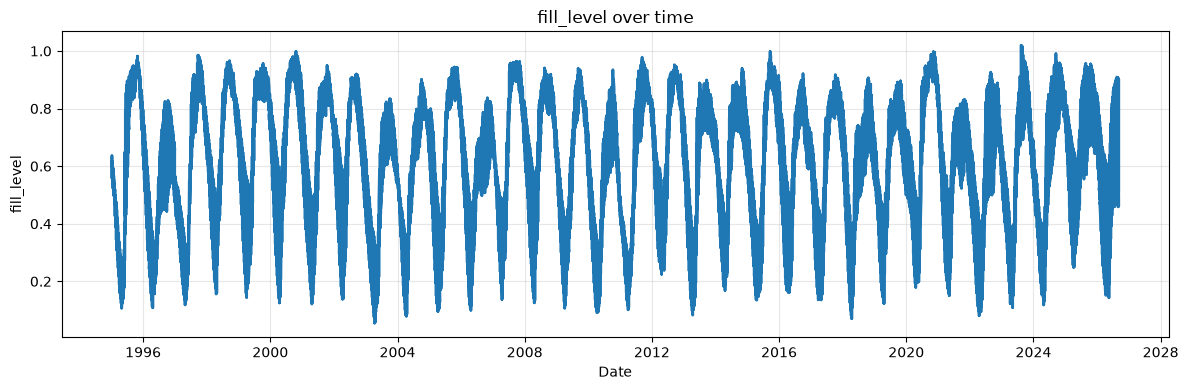

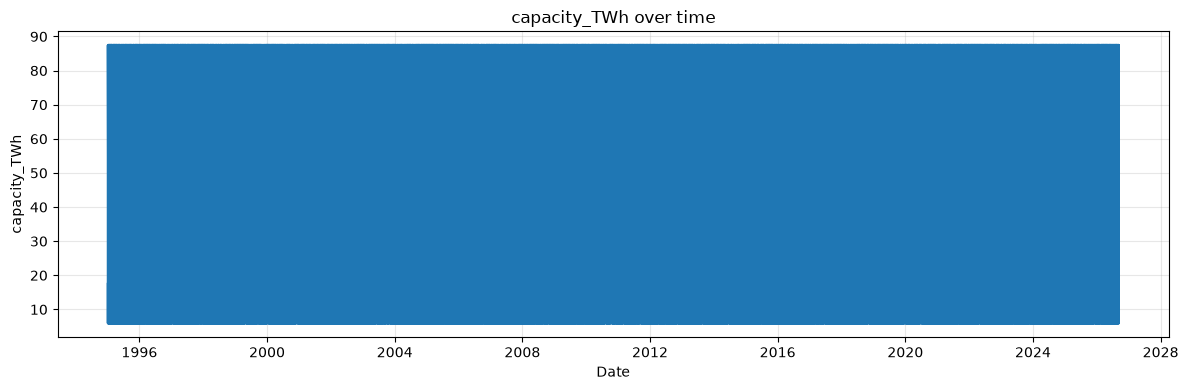

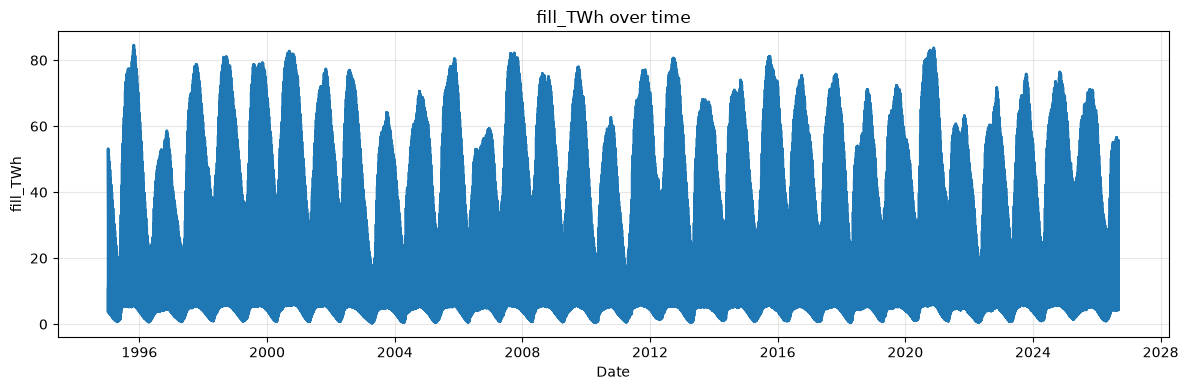

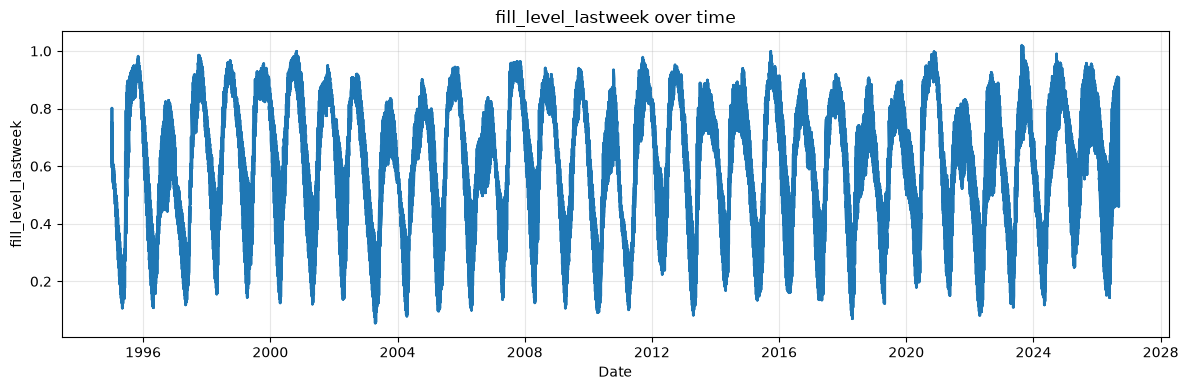

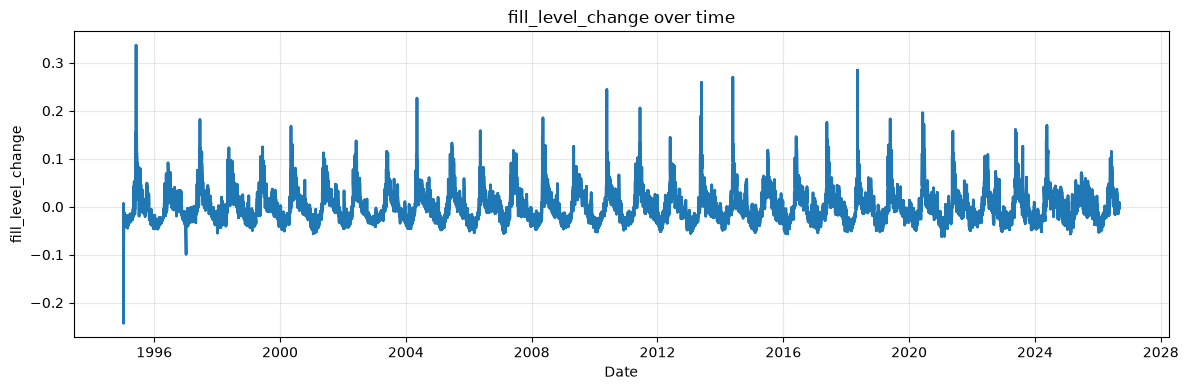

In [39]:
# Plotting the data.
# Received feedback on excluding irrelevant data such as date_Ids and iso_years.
# Implementing it now.

# Separating the numeric and categorical columns into their own lists.
numeric_columns = reservoir_df.select_dtypes(include=[np.number]).columns.drop(["areaNr", "iso_year", "iso_week"], errors='ignore')
print(numeric_columns)

categorical_columns = reservoir_df.select_dtypes(include=['object', 'str']).columns
print(categorical_columns)

for column in numeric_columns:
    plt.figure(figsize=(12, 4))
    plt.plot(reservoir_df["date_Id"], reservoir_df[column], linewidth=2)
    plt.title(f"{column} over time")
    plt.xlabel("Date")
    plt.ylabel(column)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

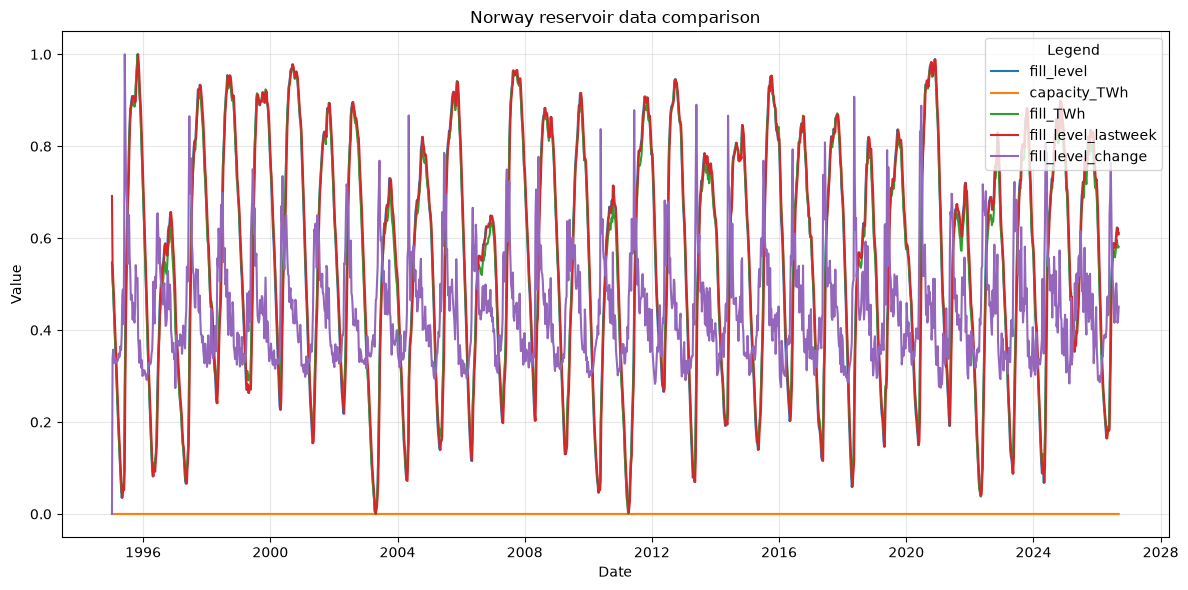

In [57]:
from sklearn.preprocessing import MinMaxScaler
# Plotting everything together.
reservoir_df_scaled = reservoir_df.copy()

# Each date has up to 6 values depending on type and location. Taking the mean gives us a more readable chart.
# This takes away information. For example, now the capacity values are different locations are represented as one mean value.
# However, this is justified for now because we just want a sneak peek at the data right now.
reservoir_df_scaled = (reservoir_df_scaled.groupby("date_Id", as_index=False)[numeric_columns].mean())

scaler = MinMaxScaler().set_output(transform="pandas")
date_column = reservoir_df_scaled['date_Id']
reservoir_df_scaled = scaler.fit_transform(reservoir_df_scaled[numeric_columns])

reservoir_df_scaled.insert(0, 'date_Id', date_column)

plt.figure(figsize=(12, 6))
for column in numeric_columns:
    plt.plot(reservoir_df_scaled["date_Id"], reservoir_df_scaled[column], label=column)
plt.title("Norway reservoir data comparison")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend(title="Legend")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()